In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("ggplot")

from scipy.optimize import brute
%config InlineBackend.format_figure = "retina"


In [17]:
import warnings
warnings.filterwarnings(action = "ignore")

In [18]:
class MACDBackTester():
    '''
    
    Attributes:
    ==========
    symbol: str
        The ticker that we want to trade.
    EMA_S: int
        Short term exponential moving average.
    EMA_L: int
        Long term exponential moving average.
    EMA_Signal:

    start: str
        The start date for the trading in YYYY-MM-DD format.
    end: str
        The end date for the trading in YYYY-MM-DD format.
    tc: float
        The trading cost for each trade (e.g. 0.001 = 0.1%)

    Methods:
    ========
    get_data():
    trading_strategy(displaying_mode = None):
    plot_results():
    set_parameters_update_strategy(new_EMA_S , new_EMA_L , new_MACD , displaying_mode = None):
    trading_strategy_optimization(EMA_S_range : (start , stop , step) , EMA_L_range : {start , stop , step))
    '''
    def __init__(self , symbol , EMA_S , EMA_L , EMA_Signal , start , end , tc):
        self.symbol = symbol
        self.EMA_S = EMA_S
        self.EMA_L = EMA_L
        self.EMA_Signal = EMA_Signal
        self.start = start
        self.end = end
        self.tc = tc
        self.data = None
        self.results = None
        self.get_data()

    def __repr__(self) -> str:
        rep = f"MACD_BackTester(symbol : {self.symbol} | EMA_S : {self.EMA_S} | EMA_L : {self.EMA_L} | EMA_Sigmal : {self.EMA_Signal} | start : {self.start} | end : {self.end} | tc : {self.tc} )"
        return rep

    def get_data(self):
        '''Load the raw price data and compute initial EMAs'''
        raw = pd.read_csv("forex_pairs.csv" , parse_dates=["Date"] , index_col=["Date"])
        raw = raw.loc[self.start : self.end , self.symbol].to_frame().dropna()
        raw.columns = ["price"]

        # Calulate the EMAs:
        raw["EMA_S"] = raw["price"].ewm(span=self.EMA_S , min_periods=self.EMA_S).mean()
        raw["EMA_L"] = raw["price"].ewm(span = self.EMA_L , min_periods = self.EMA_L).mean()
        raw["MACD"] = raw["EMA_S"] - raw["EMA_L"]
        raw["MACD_Signal"] = raw["MACD"].ewm(span=self.EMA_Signal , min_periods=self.EMA_Signal).mean()
        self.data = raw
        return raw
    
    def trading_strategy(self , displaying_mode = None):
        '''
        Implement the trading strategy & displaying its performance in comparasion with the Buy & Hold strategy in term of a value or a dataframe.
        Paramters:
        ---------
        displaying_mode : str, optional
            'tabular' : returns styled KPI table.
            'value' : return single numeric value (last element of the cummulative return of the strategy).
        '''
        data = self.data.dropna()
        data["position"] = np.where(data["MACD"]>data["MACD_Signal"] , +1 , -1)
        data["trades"] = data["position"].diff().fillna(value = 0).abs()
        data["log_ret"] = np.log(data["price"]/data["price"].shift(1))
        data["strategy"] = data["position"].shift(1) * data["log_ret"] - data["trades"] * self.tc
        data["cum_log_ret"] = np.exp(data["log_ret"].cumsum()) #Buy & Hold Value
        data["cum_strategy"] = np.exp(data["strategy"].cumsum()) #Strategy Value
        data = data.dropna()
        self.results = data

        # Extract final performance values:
        strategy_performance =  data["cum_strategy"].iloc[-1]
        buy_and_hold_performance = data["cum_log_ret"].iloc[-1]
        out_performance = strategy_performance - buy_and_hold_performance

        self.KPI = pd.DataFrame(
            {   "Strategy" :strategy_performance ,
                "Buy & Hold" : buy_and_hold_performance ,
                "Out Performance" : out_performance ,
                "Ann. Return Buy & Hold" : data["log_ret"].mean() * 252 ,
                "Ann. Return Strategy" : data["strategy"].mean() *252 ,
                "Ann. Risk Buy & Hold" : np.sqrt(data["log_ret"].var() * 252),
                "Ann. Risk Strategy" : np.sqrt(data["strategy"].var() * 252)
            },
            index = ["EMA_S:{}| EMA_L:{}".format(self.EMA_S , self.EMA_L)]
        )
        self.KPI.index.name = "Performance"

        self.KPI_table = self.KPI.T.style.format("{:.2%}")
        if displaying_mode == "tabular":
            return self.KPI_table
        elif displaying_mode == "value":
            return float(strategy_performance)
        else:
            print("Display mode not specified.")
            return None

    def plot_results(self):
        '''Plot Strategy vs Buy & Hold'''
        fig , ax = plt.subplots(figsize = (14,6))
        data = self.results
        ax.plot(data.loc[: , 'MACD'] , color = "steelblue" , lw = 3 , label = 'MACD')
        ax.plot(data.loc[: , 'MACD_Signal'] , color = "orange" , lw = 3 , label = 'MACD_Signal')
        ax.set_title(f"EURUSD: MACD | MACD_Signal | Position \n EMA_S({self.EMA_S}) | EMA_L({self.EMA_L}) | EMA_Signal({self.EMA_Signal})" , fontsize = 18)
        ax.set_ylabel("Values" , fontsize = 14)
        ax.set_xlabel("Date" , fontsize = 14)
        ax.autoscale(enable=True , axis ="x" , tight = True)
        ax.legend(loc = (0,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
        fig.gca().spines[["right" , "top"]].set_visible(False)

        ax2 = ax.twinx()
        ax2.plot(data.loc[: , 'position'] , ls = ":" , color ="green" , lw = 2.5 , label = "position")
        ax2.autoscale(enable=True , axis ="x" , tight = True)
        ax2.set_ylabel("position" , color = "green" , fontsize =13)
        ax2.set_yticks(ticks =  [-1 , +1] , 
                labels = ['-1: Short' , '+1: Long'] , color = "green")
        ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")

        plt.gca().spines[["right" , "top"]].set_visible(False)
        plt.grid(axis ="y")
        plt.tight_layout()
        plt.show()

    def set_parameters(self , new_EMA_S , new_EMA_L , new_EMA_Signal):
        '''update the new EMA_S & EMA_L parameters and recalculate the MACD , MACD_Signal on the existing data.
        '''
        if self.data is None or self.data.empty:
            raise AttributeError("Data not Loaded. Call get_data() first.")
        new_raw = self.data[["price"]].copy()
        if new_EMA_S is not None:
            self.EMA_S = new_EMA_S
        if new_EMA_L is not None:
            self.EMA_L = new_EMA_L
        if new_EMA_Signal is not None:
            self.EMA_Signal = new_EMA_Signal

        new_raw["EMA_S"] = new_raw["price"].ewm(span=self.EMA_S , min_periods=self.EMA_S).mean()
        new_raw["EMA_L"] = new_raw["price"].ewm(span = self.EMA_L , min_periods = self.EMA_L).mean()
        new_raw["MACD"] = new_raw["EMA_S"] - new_raw["EMA_L"]
        new_raw["MACD_Signal"] = new_raw["MACD"].ewm(span=self.EMA_Signal , min_periods=self.EMA_Signal).mean()
        self.data = new_raw   

    def optimized_trading_strategy(self , EMA_S_range : tuple , EMA_L_range : tuple , EMA_Signal_range : tuple):
        '''Finding
        Parameters:
        ===========
        EMA_S_range = (start , stop , step)
        EMA_L_range = (start , stop , step)
        EMA_Signal = (start , stop , step)

        Returns:
        =======-
        best_parameters: ndarray
            Array [EMA_S , EMA_L , EMA_Signal] foe the best EMA_S , EMA_L , and EMA_Signal
        best_strategy: DataFrame/Style
            DataFrame/Style
        '''

        def objective_function(x):
            self.set_parameters(x[0],x[1],x[2])
            return -1 * self.trading_strategy(displaying_mode="value")
        

        print("starting optimization ... This may take  time depending on the range size.")
        res = brute(objective_function , ranges = (EMA_S_range , EMA_L_range , EMA_Signal_range))
        best_EMA_S = res[0]
        best_EMA_L = res[1]
        best_EMA_Signal = res[2]
        print(f"Optimal Parameters found : EMA_S {best_EMA_S} | EMA_L {best_EMA_L} | EMA_Signal {best_EMA_Signal}")
        self.set_parameters(new_EMA_S = best_EMA_S , new_EMA_L = best_EMA_L , new_EMA_Signal = best_EMA_Signal)
        
        
        return self.trading_strategy(displaying_mode="tabular")



In [19]:
macd = MACDBackTester(symbol = "EURUSD=X" , EMA_S = 5 , EMA_L = 10 , EMA_Signal = 9 , start = '2010-01-01' , end = '2010-12-31' , tc = 0.00005)
macd

MACD_BackTester(symbol : EURUSD=X | EMA_S : 5 | EMA_L : 10 | EMA_Sigmal : 9 | start : 2010-01-01 | end : 2010-12-31 | tc : 5e-05 )

In [20]:
macd.get_data()

,price,EMA_S,EMA_L,MACD,MACD_Signal
Date,,,,,
2010-01-01,1.438994,NaN,NaN,NaN,NaN
2010-01-04,1.442398,NaN,NaN,NaN,NaN
2010-01-05,1.436596,NaN,NaN,NaN,NaN
2010-01-06,1.440403,NaN,NaN,NaN,NaN
2010-01-07,1.431803,1.436572,NaN,NaN,NaN
...,...,...,...,...,...
2010-12-27,1.307976,1.311942,1.316046,-0.004104,-0.003506
2010-12-28,1.318965,1.314283,1.316577,-0.002293,-0.003263
2010-12-29,1.308627,1.312398,1.315131,-0.002733,-0.003157


In [21]:
macd.trading_strategy(displaying_mode="tabular")

Performance,EMA_S:5| EMA_L:10
Strategy,98.50%
Buy & Hold,94.45%
Out Performance,4.04%
Ann. Return Buy & Hold,-5.92%
Ann. Return Strategy,-1.57%
Ann. Risk Buy & Hold,12.04%
Ann. Risk Strategy,12.07%


In [22]:
macd.trading_strategy(displaying_mode="value")

0.984955049357668

In [23]:
macd.set_parameters(20 , 30, 12)

In [24]:
macd.trading_strategy(displaying_mode='tabular')

Performance,EMA_S:20| EMA_L:30
Strategy,119.41%
Buy & Hold,97.58%
Out Performance,21.83%
Ann. Return Buy & Hold,-2.81%
Ann. Return Strategy,20.32%
Ann. Risk Buy & Hold,12.18%
Ann. Risk Strategy,12.12%


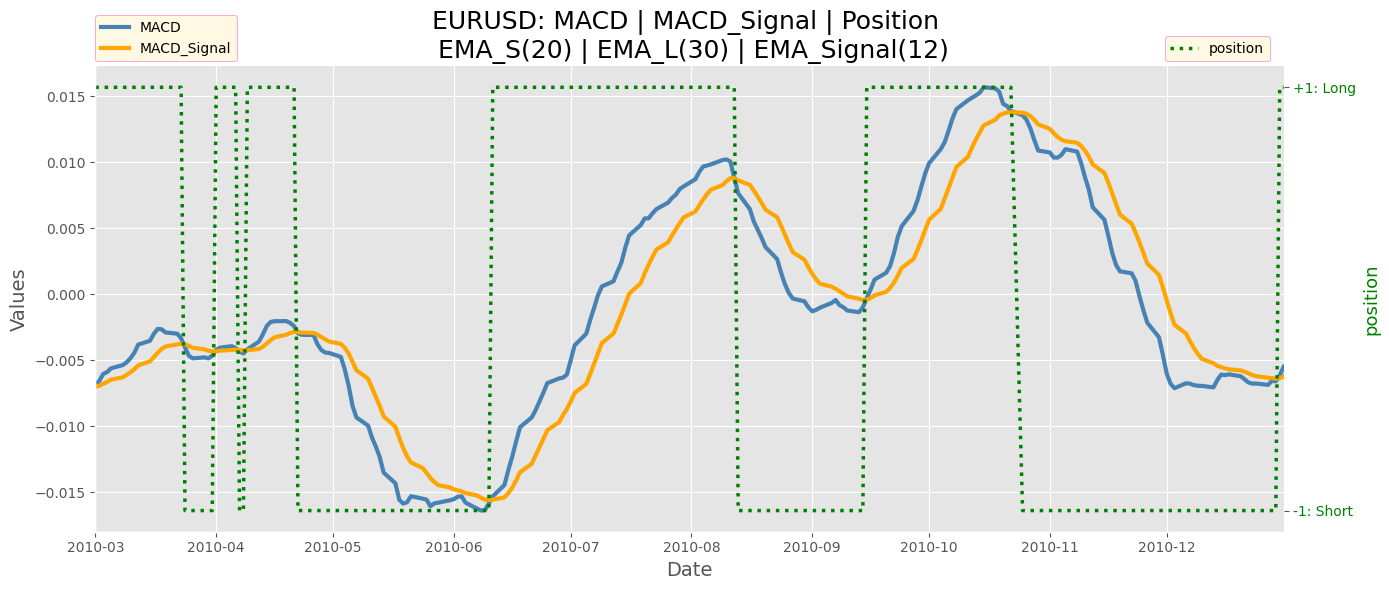

In [25]:
macd.plot_results()

In [33]:
macd.optimized_trading_strategy(EMA_S_range=(1,70,1) , EMA_L_range=(70,200,1) , EMA_Signal_range=(1,30,1))

starting optimization ... This may take  time depending on the range size.
Optimal Parameters found : EMA_S 20.666666666666664 | EMA_L 68.39999999999999 | EMA_Signal 15.5


Performance,EMA_S:20.666666666666664| EMA_L:68.39999999999999
Strategy,124.71%
Buy & Hold,99.25%
Out Performance,25.46%
Ann. Return Buy & Hold,-1.05%
Ann. Return Strategy,31.09%
Ann. Risk Buy & Hold,12.82%
Ann. Risk Strategy,12.67%


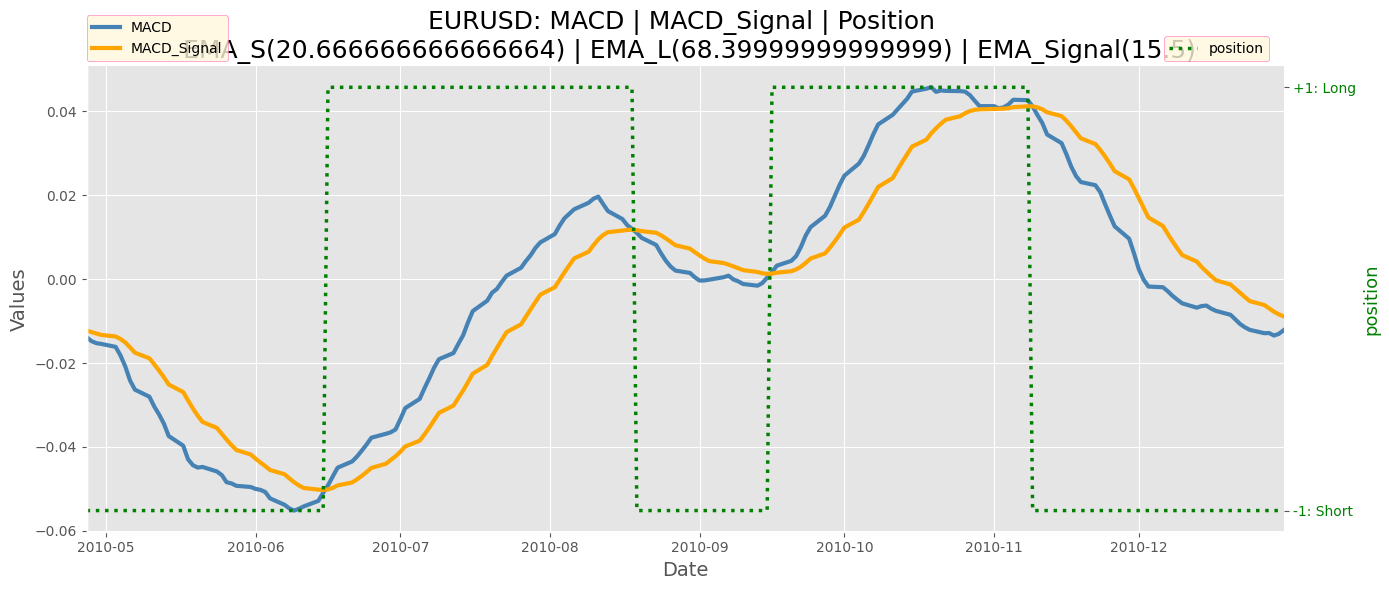

In [34]:
macd.plot_results()